<a href="https://colab.research.google.com/github/IvanMusila/tajirika/blob/ml%2Fdata-preparation/01_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tajirika - Notebook 1: Data Preparation
Turns the Safaricom M-PESA statement PDF into a labeled CSV for the three models.

**Run order:** 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 7 -> 8 -> 9 -> 10.
Cells 4 to 8 are safe to re-run (each starts from a clean copy). The optional checks at the bottom are not part of the pipeline.

## Cell 1 - Install and imports

In [ ]:
!pip install pdfplumber -q

import re
import pdfplumber
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 79.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 68.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## Cell 2 - Mount Drive and set paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/Tajirika'
PDF_PATH   = f'{DRIVE_BASE}/data/sample_transactions/mpesa_statement.pdf'
OUTPUT_CSV = f'{DRIVE_BASE}/data/transactions_labeled.csv'
INCOME_CSV = f'{DRIVE_BASE}/data/transactions_income.csv'

Path(f'{DRIVE_BASE}/data').mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## Cell 3 - Read the PDF (slow: ~203 pages, run once)

In [ ]:
def parse_mpesa_pdf(pdf_path):
    """Extract every transaction row from a Safaricom M-PESA statement PDF."""
    rows = []
    SKIP_DETAILS  = {'OverDraft of Credit Party'}   # Fuliza accounting entries, not real transactions
    HEADER_VALUES = {'Receipt No.', 'Receipt No', 'TRANSACTION TYPE',
                     'Statement Verification Code', ''}

    with pdfplumber.open(pdf_path) as pdf:
        total = len(pdf.pages)
        print(f"Processing {total} pages...")
        for i, page in enumerate(pdf.pages):
            if i % 20 == 0:
                print(f"  Page {i+1}/{total}")
            for table in page.extract_tables():
                for row in table:
                    if not row or len(row) < 7:
                        continue
                    receipt = str(row[0]).strip() if row[0] else ''
                    if not receipt or receipt in HEADER_VALUES:
                        continue
                    details = str(row[2]).replace('\n', ' ').strip() if row[2] else ''
                    if details in SKIP_DETAILS:
                        continue
                    rows.append({
                        'receipt_no': receipt,
                        'timestamp':  str(row[1]).strip() if row[1] else '',
                        'details':    details,
                        'status':     str(row[3]).strip() if row[3] else '',
                        'paid_in':    str(row[4]).strip() if row[4] else '',
                        'withdrawn':  str(row[5]).strip() if row[5] else '',
                        'balance':    str(row[6]).strip() if row[6] else '',
                    })

    print(f"Done. Raw rows extracted: {len(rows)}")
    return pd.DataFrame(rows)

raw_pdf_df = parse_mpesa_pdf(PDF_PATH)     # untouched copy; later cells always start from this
raw_pdf_df.head(10)

Processing 203 pages...
  Page 1/203
  Page 21/203
  Page 41/203
  Page 61/203
  Page 81/203
  Page 101/203
  Page 121/203
  Page 141/203
  Page 161/203
  Page 181/203
  Page 201/203
Done. Raw rows extracted: 6577


,receipt_no,timestamp,details,status,paid_in,withdrawn,balance
0,UIU5E8OJJ9,2026-09-30 19:02:51,Merchant Payment Online to 7261360 - JAVA KUKI...,Completed,,-460.00,82.70
1,UIU5E8OJDX,2026-09-30 18:59:18,Customer Transfer of Funds Charge,Completed,,-7.00,542.70
2,UIU5E8OJDX,2026-09-30 18:59:18,Customer Transfer to - 254703***476 Kelvin Andago,Completed,,-120.00,549.70
3,UIU5E8O698,2026-09-30 17:25:58,Customer Transfer of Funds Charge,Completed,,-7.00,669.70
4,UIU5E8O698,2026-09-30 17:25:58,Customer Transfer to - 254796***523 ANATHE KAAYA,Completed,,-150.00,676.70
5,UIU5E8O3IO,2026-09-30 17:17:55,Recharge for Customer to 4093441SAFARICOM DATA...,Completed,,-20.00,826.70
6,UIT5E8IJ6B,2026-09-29 13:07:52,Customer Transfer to - 254720***299 MOMANYI BE...,Completed,,-30.00,846.70
7,UIT5E8I3F0,2026-09-29 10:49:52,Customer Payment to Small Business to - 254724...,Completed,,-50.00,876.70
8,UIT5E8HZ7C,2026-09-29 10:40:59,Customer Payment to Small Business to - 254110...,Completed,,-70.00,926.70
9,UIT5E8HQAG,2026-09-29 08:32:54,Customer Transfer of Funds Charge,Completed,,-7.00,996.70


## Cell 4 - Clean amounts and timestamps

In [ ]:
def clean_amount(val):
    """'1,234.00' -> 1234.0 | '-460.00' -> 460.0 | '' -> 0.0  (direction comes from the column)"""
    if val is None:
        return 0.0
    cleaned = re.sub(r'[^0-9.]', '', str(val))
    return float(cleaned) if cleaned else 0.0

raw_df = raw_pdf_df.copy()

raw_df['amount_in']  = raw_df['paid_in'].apply(clean_amount)
raw_df['amount_out'] = raw_df['withdrawn'].apply(clean_amount)
raw_df['balance']    = raw_df['balance'].apply(clean_amount)
raw_df['amount']     = raw_df.apply(
    lambda r: r['amount_out'] if r['amount_out'] > 0 else r['amount_in'], axis=1)

raw_df['timestamp'] = pd.to_datetime(raw_df['timestamp'], errors='coerce')

raw_df = raw_df[raw_df['amount'] > 0].copy()
raw_df = raw_df.dropna(subset=['timestamp'])
raw_df = raw_df.sort_values('timestamp').reset_index(drop=True)

print(f"Clean rows: {len(raw_df)}")
print(f"Date range: {raw_df['timestamp'].min().date()} -> {raw_df['timestamp'].max().date()}")
raw_df[['timestamp', 'details', 'amount_in', 'amount_out', 'balance']].head(10)

Clean rows: 6577
Date range: 2024-01-04 -> 2026-09-30


,timestamp,details,amount_in,amount_out,balance
0,2024-01-04 11:28:38,Funds received from - 254718***994 ROSE MUSILA,500.0,0.0,547.61
1,2024-01-04 11:57:40,Customer Transfer to - 0759***825 samuel joseph,0.0,70.0,477.61
2,2024-01-04 12:08:27,Customer Transfer to - 0726***264 Javan Otieno,0.0,80.0,397.61
3,2024-01-04 13:29:04,Pay Bill Online to 247247 - Equity Paybill Acc...,0.0,60.0,337.61
4,2024-01-04 13:30:23,Pay Bill Online to 247247 - Equity Paybill Acc...,0.0,20.0,317.61
5,2024-01-04 14:23:39,Customer Payment to Small Business to - 254724...,0.0,40.0,277.61
6,2024-01-04 14:33:05,Merchant Payment to 6041928 - JULIUS SINDIYO T...,0.0,50.0,227.61
7,2024-01-04 15:06:56,Customer Payment to Small Business to - 254745...,0.0,70.0,157.61
8,2024-01-04 15:31:31,Customer Transfer to - 254740***054 Dison MUTUA,0.0,100.0,57.61
9,2024-01-05 12:26:52,Funds received from - 254718***994 ROSE MUSILA,1500.0,0.0,1557.61


## Cell 5 - Work out what each transaction is (type, merchant name, merchant id)

In [ ]:
def extract_fields(details):
    """Parse the Details text into transaction_type, merchant_name, merchant_id."""
    d = str(details).strip()

    def out(t, name, mid):
        return {'transaction_type': t, 'merchant_name': name, 'merchant_id': mid}

    # 0. Blank details (Safaricom leaves some cells empty)
    if not d:
        return out('unknown', 'Unknown', 'unknown')

    # 1. Fees
    if re.search(r'(Transfer of Funds Charge|Pay Bill Charge|Pay Merchant Charge|Withdrawal Charge)', d, re.I):
        return out('fee', 'M-Pesa Fee', 'mpesa_fee')

    # 2. Reversals (money coming back)
    if re.search(r'reversal', d, re.I):
        return out('receive_money', 'Payment Reversal', 'reversal')

    # 3. Savings and investments
    if re.match(r'Unit Trust Withdraw', d, re.I):
        return out('receive_money', 'Ziidi MMF', '4145555')
    if re.match(r'M-Shwari Withdraw', d, re.I):
        return out('receive_money', 'M-Shwari', 'mshwari')
    if re.match(r'Sell Shares Payment', d, re.I):
        return out('receive_money', 'Ziidi Trader', '4157363')
    if re.match(r'(Unit Trust Invest|Ziidi Trader Customer Payment)', d, re.I):
        return out('savings_deposit', 'Ziidi MMF', '4145555')
    if re.match(r'M-Shwari Deposit', d, re.I):
        return out('savings_deposit', 'M-Shwari', 'mshwari')

    # 4. Money received
    m = re.match(r'Funds received from\s*(?:[-–]\s*)?([\d\*]+)\s*(?:[-–]\s*)?(.+)', d, re.I)
    if m:
        return out('receive_money', m.group(2).strip().title(), m.group(1).strip())
    for pat in (r'Merchant Customer Payment from\s+(\d+)\s*[-–]\s*(.+)',
                r'Business Payment from\s+(\d+)\s*[-–]\s*(.+?)(?:\s+via\s+.+)?$',
                r'Deposit of Funds at Agent Till\s+(\d+)\s*[-–]\s*(.+)'):
        m = re.match(pat, d, re.I)
        if m:
            return out('receive_money', m.group(2).strip().title(), m.group(1).strip())

    # 5. Loan repayment (Fuliza / OD)
    if re.match(r'OD Loan Repayment', d, re.I):
        return out('loan_repayment', 'M-Pesa Overdraw', '232323')

    # 6. Airtime and data bundles
    if re.search(r'(Recharge for Customer|Bundle Purchase|Buy Bundles|Airtime Purchase)', d, re.I):
        if re.search(r'DATA BUNDLE|SAFARICOM DATA|Buy Bundles', d, re.I):
            return out('data_bundle', 'Safaricom Data', '4093441')
        return out('airtime', 'Airtime', 'airtime')

    # 7. Agent withdrawals (normal and with Fuliza)
    m = re.match(r'Customer Withdrawal.*?(?:Till|to)\s+(\d+)\s*[-–]\s*(.+)', d, re.I)
    if m:
        return out('withdrawal', m.group(2).strip().title()[:40], m.group(1).strip())

    # 8. Send money (person to person, small business, Fuliza variants)
    m = re.match(r'Customer Transfer to\s+(254\d{9}|0\d{9})\s*[-–]\s*(.+)', d, re.I)   # unmasked number
    if m:
        return out('send_money', m.group(2).strip().title(), m.group(1).strip())
    m = re.match(r'Offnet C2B Transfer to\s+(\d+)\s*[-–]\s*(.+?)(?:\.\s+for.+)?$', d, re.I)
    if m:
        return out('send_money', m.group(2).strip().title(), m.group(1).strip())
    m = re.search(r'(?:Transfer|Send Money|Payment to Small Business)\s+.*?to\s*[-–]\s*([\d\*]+)\s+(.+)', d, re.I)
    if m:
        return out('send_money', m.group(2).strip().title(), m.group(1).strip())

    # 9. Buy goods (till payments)
    m = re.match(r'Merchant Payment.*?to\s+(\d+)\s*[-–]\s*(.+)', d, re.I)
    if m:
        return out('buy_goods', m.group(2).strip().title(), m.group(1).strip())

    # 10. Paybill
    m = re.match(r'(?:Card\s+)?Pay Bill.*?to\s+(\d+)\s*[-–]\s*(.+)', d, re.I)
    if m:
        name = re.sub(r'\s+Acc\..*$', '', m.group(2)).strip()
        return out('paybill', name.title(), m.group(1).strip())

    # 11. Fallback
    return out('other', d[:60].title(), '')


# Re-run safe: drop columns from a previous run before adding them again
raw_df = raw_df.drop(columns=['transaction_type', 'merchant_name', 'merchant_id'], errors='ignore')
fields = raw_df['details'].apply(extract_fields).apply(pd.Series)
raw_df = pd.concat([raw_df, fields], axis=1)

print(raw_df['transaction_type'].value_counts())
print(f"\nUnique merchants: {raw_df['merchant_name'].nunique()}")

transaction_type
send_money         2184
buy_goods          1088
fee                 970
receive_money       790
paybill             448
data_bundle         438
loan_repayment      354
unknown             121
savings_deposit      98
airtime              60
withdrawal           26
Name: count, dtype: int64

Unique merchants: 1713


## Cell 6 - Label merchants (everything except person-to-person sends)

In [ ]:
# merchant_id -> (category, clean name)
MERCHANT_ID_MAP = {
    # Necessity
    '4076367': ('necessity',    'Beech Properties (Rent)'),
    '828169':  ('necessity',    'Springreen Stima (Electricity)'),
    '644028':  ('necessity',    'Moja Expressway (Toll)'),
    '247247':  ('necessity',    'Equity Bank Paybill'),
    '5047995': ('necessity',    'Strathmore Catering'),
    '515037':  ('necessity',    'Naivas Syokimau'),
    '7110257': ('necessity',    'Naivas Kilimani'),
    '7527036': ('necessity',    'Naivas Ojijo Road'),
    '6780943': ('necessity',    'Naivas Langata'),
    '118872':  ('necessity',    'Quick Mart Embakasi'),
    '7053097': ('necessity',    'Quick Mart Tmall'),
    # Convenience
    '7261360': ('convenience',  'Java Coffee'),
    '7448346': ('convenience',  'Wrapped Foods'),
    '271921':  ('convenience',  'KFC Hurlingham'),
    '9436547': ('convenience',  'Hot Plate Kitchens'),
    '5471958': ('convenience',  'Samosa World'),
    '319490':  ('convenience',  'Shawarma Hub'),
    '4093441': ('convenience',  'Safaricom Data'),
    # Aspirational
    '6681693': ('aspirational', 'Dukani Digital'),
    '900550':  ('aspirational', 'Parklands Sports Club'),
    '903470':  ('aspirational', 'Apple Subscriptions'),
    '691918':  ('aspirational', 'Pins Entertainment'),
    '6709296': ('aspirational', 'House Of Leather'),
    '200576':  ('aspirational', 'Afontana Books'),
    # Social
    '933333':  ('social',       'CITAM Embakasi (Church)'),
    # Invisible
    'mpesa_fee': ('invisible',  'M-Pesa Fee'),
    '232323':    ('invisible',  'M-Pesa Overdraw Repayment'),
    '303030':    ('invisible',  'Absa Bank'),
    '400200':    ('invisible',  'Co-op Bank Transfer'),
    'mshwari':   ('invisible',  'M-Shwari Savings'),
}

# More merchants from your statement (category only)
EXTRA_ID_MAP = {
    # Necessity
    '754100': 'necessity',    # Acacia Vale Properties (rent)
    '3547167': 'necessity',   # Maa Properties
    '222222': 'necessity',    # E-Citizen
    '644024': 'necessity',    # Moja Expressway
    '4037539': 'necessity',   # Pharma Plus
    '912474': 'necessity',    # Optica House
    '774227': 'necessity',    # Karen Provision Stores
    '748447': 'necessity',    # Francy Enterprises (confirm)
    # Convenience
    '7229290': 'convenience', '896914': 'convenience', '6199060': 'convenience',
    '959419': 'convenience',  '147977': 'convenience', '7528605': 'convenience',
    '6642880': 'convenience', '6270083': 'convenience', '9120346': 'convenience',
    '826915': 'convenience',
    # Aspirational
    '7284599': 'aspirational', '6242041': 'aspirational', '6861731': 'aspirational',
    '989675': 'aspirational',  '6289986': 'aspirational', '220432': 'aspirational',
    '614250': 'aspirational',  '4040305': 'aspirational', '290290': 'aspirational',
    # Social
    '513500': 'social',       # Kenya Children Homes
    # Invisible (banks, aggregators)
    '8250250': 'invisible', '522522': 'invisible', '522533': 'invisible',
    '516600': 'invisible',  '7983412': 'invisible', '222111': 'invisible',
    '880100': 'invisible',  '542542': 'invisible', '220333': 'invisible',
    '510800': 'invisible',  '493373': 'invisible', '804200': 'invisible',
    '3035825': 'invisible',
    '6361826': 'social',        # Lee Mark Nyoike (chama contributions)
    '807098':  'convenience',   # Ngong Road Dad (Pizza Inn)
    '7031616': 'convenience',   # TotalEnergies Hurlingham (fuel)
    '7140609': 'convenience',   # Dad Syokimau (likely another Pizza Inn branch, confirm)
    '756723':  'aspirational',  # Parklands Sports Club (second till)
    '7099197': 'aspirational',  # Century Cinemax (cinema)
    '547026':  'aspirational',  # Mustard Accessories
    '827473':  'convenience',   # Big Knife (restaurant)
}

# Keyword rules: whole-word match, merchants only (never applied to P2P names)
KEYWORD_RULES = [
    (r'naivas|quick\s?mart|carrefour|cleanshelf|supermarket|grocery', 'necessity'),
    (r'kplc|kenya power|water|electricity|stima|rent|landlord|properties', 'necessity'),
    (r'hospital|clinic|pharmacy|chemist|dawa|doctor|dispensary|medical', 'necessity'),
    (r'matatu|bus|transport|fare|uber|bolt|shuttle', 'necessity'),
    (r'school|college|university|fees|expressway|toll', 'necessity'),

    (r'java|artcaffe|kfc|pizza|chicken|restaurant|cafe|hotel|grill', 'convenience'),
    (r'wrapped|samosa|shawarma|kitchen|foods?|catering|juice', 'convenience'),
    (r'airtime|data bundles?|bundles', 'convenience'),
    (r'glovo|delivery|petrol|shell|kenol|kobil|fuel|station|totalenergies', 'convenience'),

    (r'church|citam|pcea|catholic|tithe|offering|harambee|wedding|funeral|chama|sacco', 'social'),

    (r'salon|barber|spa|beauty|nails?|hair|gym|fitness|yoga|sports club', 'aspirational'),
    (r'netflix|showmax|dstv|spotify|apple|subscription|jumia|kilimall', 'aspirational'),
    (r'clothing|fashion|shoes|leather|boutique|entertainment|cinema|cinemax|lounge|bar|clubs?|clubs?\d|books?|accessories', 'aspirational'),

    (r'm-pesa fee|transaction fee|charge|fuliza|overdraw|m-shwari|bank', 'invisible'),
]

def auto_label(row):
    """Returns (category, label_source)."""
    t_type   = str(row['transaction_type']).lower()
    m_id     = str(row['merchant_id'])
    merchant = str(row['merchant_name']).lower()

    # 1. Type-based rules
    if t_type in ('fee', 'loan_repayment', 'savings_deposit'): return 'invisible', 'rule'
    if t_type == 'receive_money':                              return 'income', 'rule'
    if t_type == 'withdrawal':                                 return 'necessity', 'rule'
    if t_type in ('airtime', 'data_bundle'):                   return 'convenience', 'rule'

    # 2. Hand off to Cell 7 (names can't be keyword-matched reliably)
    if t_type in ('send_money', 'unknown'):                    return 'review', 'rule'

    # 3. Merchant ID lookups (highest confidence)
    if m_id in MERCHANT_ID_MAP:                                return MERCHANT_ID_MAP[m_id][0], 'id_map'
    if m_id in EXTRA_ID_MAP:                                   return EXTRA_ID_MAP[m_id], 'id_map'

    # 4. Keyword rules
    for pattern, category in KEYWORD_RULES:
        if re.search(rf'\b(?:{pattern})\b', merchant, re.I):
            return category, 'keyword'

    # 5. Long-tail defaults (low confidence)
    if t_type == 'buy_goods': return 'convenience', 'default_low_confidence'
    if t_type == 'paybill':   return 'invisible',   'default_low_confidence'

    return 'review', 'rule'

labels = raw_df.apply(auto_label, axis=1, result_type='expand')
raw_df['category']     = labels[0]
raw_df['label_source'] = labels[1]

# Clean display names for known merchant ids
raw_df['merchant_name'] = raw_df.apply(
    lambda r: MERCHANT_ID_MAP[str(r['merchant_id'])][1]
              if str(r['merchant_id']) in MERCHANT_ID_MAP else r['merchant_name'], axis=1)

print(raw_df['category'].value_counts())
print("\nStill in review (Cell 7 handles these):")
print(raw_df[raw_df['category'] == 'review']['transaction_type'].value_counts())
print("\nLabel sources:")
print(raw_df['label_source'].value_counts())

category
review          2305
invisible       1534
convenience     1038
income           790
necessity        490
aspirational     325
social            95
Name: count, dtype: int64

Still in review (Cell 7 handles these):
transaction_type
send_money    2184
unknown        121
Name: count, dtype: int64

Label sources:
label_source
rule                      5041
id_map                    1234
default_low_confidence     157
keyword                    145
Name: count, dtype: int64


## Cell 7 - Label person-to-person sends and blank-details rows

In [ ]:
SEND_MONEY_OVERRIDES = {
    r'Grace Amoi':   'social',   # partner
    r'Mark Njoroge': 'social',   # friend
    r'Joy Musila':   'social',   # family (change if wrong)
}

def override_send_money(row):
    if row['category'] != 'review' or row['transaction_type'] != 'send_money':
        return row['category']
    # Paid as Small Business / Micro SME = a purchase, not a social send
    if re.search(r'Small Business|Micro SME', str(row['details']), re.I):
        return 'convenience'
    for pattern, cat in SEND_MONEY_OVERRIDES.items():
        if re.search(pattern, str(row['merchant_name']), re.I):
            return cat
    return 'social'   # default: unlabeled P2P send

# Blank-details rows, labeled by amount (a guess, flagged as such below)
BLANK_AMOUNT_MAP = {
    20.0: 'convenience', 50.0: 'convenience', 10.0: 'convenience', 5.0: 'convenience',
    99.0: 'invisible',   26.0: 'invisible',   28.0: 'invisible',   52.0: 'invisible',
    1000.0: 'invisible', 500.0: 'invisible',
}

def override_unknowns(row):
    if row['transaction_type'] != 'unknown':
        return row['category']
    return BLANK_AMOUNT_MAP.get(row['amount_out'], 'review')

# Mark which rows these functions are about to label
sends   = (raw_df['category'] == 'review') & (raw_df['transaction_type'] == 'send_money')
unknown = (raw_df['transaction_type'] == 'unknown')

raw_df['category'] = raw_df.apply(override_send_money, axis=1)
raw_df['category'] = raw_df.apply(override_unknowns, axis=1)

raw_df.loc[sends,   'label_source'] = 'p2p_rule'
raw_df.loc[unknown, 'label_source'] = 'amount_guess'

print(raw_df['category'].value_counts())
print("\nStill in review:")
print(raw_df[raw_df['category'] == 'review'][['receipt_no', 'transaction_type', 'amount', 'details']])

category
convenience     1804
social          1612
invisible       1553
income           790
necessity        490
aspirational     325
review             3
Name: count, dtype: int64

Still in review:
      receipt_no transaction_type  amount details
1566  SIJ86V9GOM          unknown   23.00        
5115  UCF5E9IRXT          unknown  150.00        
5118  UCF5E9IPY3          unknown  946.19        


## Cell 8 - Build the final expense and income tables

In [ ]:
# Time features
raw_df['date']        = raw_df['timestamp'].dt.date
raw_df['hour']        = raw_df['timestamp'].dt.hour
raw_df['day_of_week'] = raw_df['timestamp'].dt.dayofweek
raw_df['month']       = raw_df['timestamp'].dt.month
raw_df['year']        = raw_df['timestamp'].dt.year
raw_df['is_debit']    = raw_df['amount_out'] > 0

# Income table. Some "income" is really your own money coming back; tag it so
# the forecasting notebook can exclude it when computing runway.
SAVINGS_RETURN_NAMES = {'M-Shwari', 'M-Shwari Savings', 'Ziidi MMF', 'Ziidi Trader', 'Payment Reversal', 'Lee Mark Nyoike'}
income_df = raw_df[raw_df['category'] == 'income'].copy()
income_df['income_kind'] = income_df['merchant_name'].apply(
    lambda n: 'savings_or_reversal' if n in SAVINGS_RETURN_NAMES else 'income')

# Expense table: everything that is not income, and not left unresolved
expenses_df = raw_df[~raw_df['category'].isin(['income', 'review'])].copy()

final_df = expenses_df[[
    'receipt_no', 'timestamp', 'date', 'hour', 'day_of_week', 'month', 'year',
    'merchant_name', 'merchant_id', 'transaction_type',
    'amount', 'amount_in', 'amount_out', 'balance',
    'category', 'label_source', 'is_debit', 'details'
]].copy()

print(f"Expense rows: {len(final_df)}")
print(f"Income rows:  {len(income_df)}")
print(f"Date range: {final_df['timestamp'].min().date()} -> {final_df['timestamp'].max().date()}")
print("\nCategory distribution:")
print(final_df['category'].value_counts())
print("\nTransaction types:")
print(final_df['transaction_type'].value_counts())

Expense rows: 5784
Income rows:  790
Date range: 2024-01-04 -> 2026-09-30

Category distribution:
category
convenience     1804
social          1612
invisible       1553
necessity        490
aspirational     325
Name: count, dtype: int64

Transaction types:
transaction_type
send_money         2184
buy_goods          1088
fee                 970
paybill             448
data_bundle         438
loan_repayment      354
unknown             118
savings_deposit      98
airtime              60
withdrawal           26
Name: count, dtype: int64


## Cell 9 - Save to Drive

In [ ]:
final_df.to_csv(OUTPUT_CSV, index=False)
income_df.to_csv(INCOME_CSV, index=False)
print(f"Saved {len(final_df)} expense rows -> {OUTPUT_CSV}")
print(f"Saved {len(income_df)} income rows  -> {INCOME_CSV}")

Saved 5784 expense rows -> /content/drive/MyDrive/Tajirika/data/transactions_labeled.csv
Saved 790 income rows  -> /content/drive/MyDrive/Tajirika/data/transactions_income.csv


## Cell 10 - Sanity-check charts

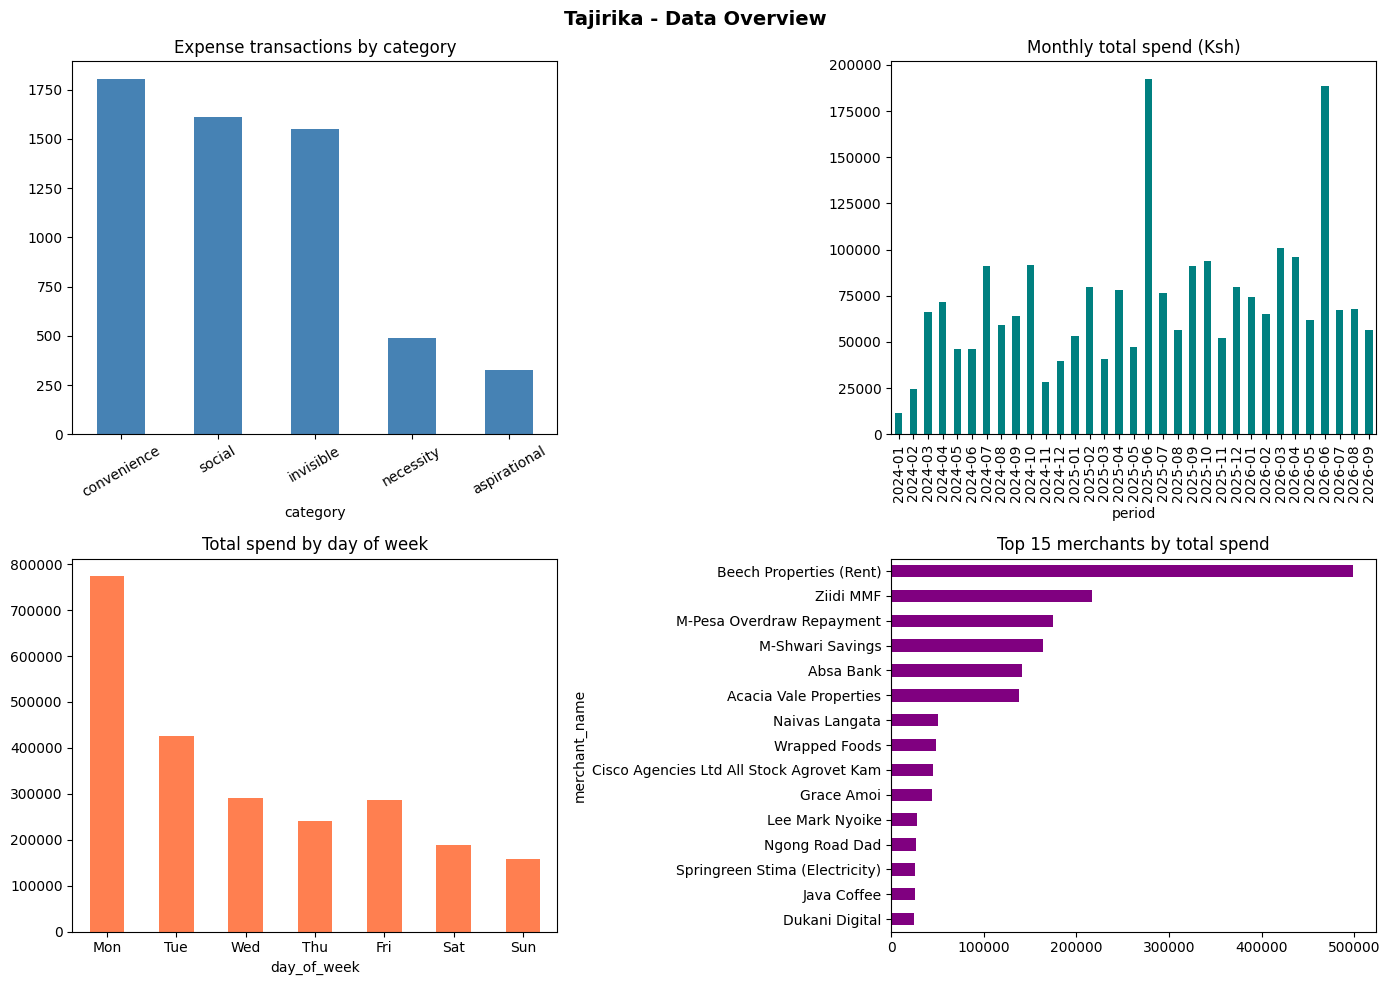

In [ ]:
debit_df = final_df[final_df['is_debit']]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Tajirika - Data Overview', fontsize=14, fontweight='bold')

# 1. Transactions by category
debit_df['category'].value_counts().plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Expense transactions by category')
axes[0, 0].tick_params(axis='x', rotation=30)

# 2. Monthly spend
monthly = debit_df.groupby(['year', 'month'])['amount'].sum().reset_index()
monthly['period'] = monthly['year'].astype(str) + '-' + monthly['month'].astype(str).str.zfill(2)
monthly.plot(x='period', y='amount', kind='bar', ax=axes[0, 1], legend=False, color='teal')
axes[0, 1].set_title('Monthly total spend (Ksh)')
axes[0, 1].tick_params(axis='x', rotation=90)

# 3. Spend by day of week
debit_df.groupby('day_of_week')['amount'].sum().plot(kind='bar', ax=axes[1, 0], color='coral')
axes[1, 0].set_title('Total spend by day of week')
axes[1, 0].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], rotation=0)

# 4. Top 15 merchants
debit_df.groupby('merchant_name')['amount'].sum().sort_values(ascending=False).head(15)\
    .plot(kind='barh', ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Top 15 merchants by total spend')
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.savefig(f'{DRIVE_BASE}/data/eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Optional checks (not part of the pipeline)
Run these only when you want to investigate something. They never change your data.

### Check A - How trustworthy are the labels?

In [ ]:
print(final_df['label_source'].value_counts())
print()
print(pd.crosstab(final_df['category'], final_df['label_source']))

label_source
p2p_rule                  2184
rule                      1946
id_map                    1234
default_low_confidence     157
keyword                    145
amount_guess               118
Name: count, dtype: int64

label_source  amount_guess  default_low_confidence  id_map  keyword  p2p_rule  \
category                                                                        
aspirational             0                       0     287       38         0   
convenience             99                     135     377       28       667   
invisible               19                      22      88        2         0   
necessity                0                       0     390       74         0   
social                   0                       0      92        3      1517   

label_source  rule  
category            
aspirational     0  
convenience    498  
invisible     1422  
necessity       26  
social           0  


### Check B - Biggest merchants stuck on low-confidence defaults

In [ ]:
low = final_df[final_df['label_source'] == 'default_low_confidence']
print(low.groupby(['transaction_type', 'merchant_id', 'merchant_name'])['amount']
         .agg(['count', 'sum']).sort_values('sum', ascending=False).head(20))

                                                          count     sum
transaction_type merchant_id merchant_name                             
buy_goods        5150929     Tufyfo Services Ltd              4  3125.0
                 6366839     Sheila Wambui Wanjeru            1  2500.0
                 7649818     Mary Njeri 33                    1  2200.0
paybill          4130673     Noortech Mobile (K) Limited      1  2100.0
buy_goods        7760245     Puffin Impex Limited 1           5  1855.0
paybill          672683      Guiderig Solutions Limited       1  1740.0
buy_goods        7008105     Fortunatus Maingi Nguutu         1  1600.0
paybill          927633      Direct Pay Hq                    1  1300.0
                 4034615     Gladys Technologies Limited      1   906.0
buy_goods        5974070     Ernest Inyanya Liabeya           1   660.0
                 8196613     Benard Ontita Omweri             1   650.0
                 6473003     Christine Katunge Kalato         2 

### Check C - Any rows still unresolved or unrecognised?

In [ ]:
print("Unresolved (category = review):", (raw_df['category'] == 'review').sum())
print("Unrecognised (type = other):   ", (raw_df['transaction_type'] == 'other').sum())
print(raw_df[raw_df['transaction_type'] == 'other']['details'].value_counts().head(20))

Unresolved (category = review): 3
Unrecognised (type = other):    0
Series([], Name: count, dtype: int64)
